# **Task 1: Student Performance Dataset Analysis**

**Drive Mounting**

In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Importing Packages**

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load Dataset (csv file)**

In [56]:
df=pd.read_csv('/content/drive/MyDrive/aiml_datasets/Student_Performance.csv')

# **Dataset Summary**

**Preview of first 5 rows**

In [57]:
df.head()

,student_id,age,gender,parent_education,study_hours,attendance_percentage,internet_access,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,post graduate,3.1,84.3,yes,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,graduate,3.7,87.8,yes,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,post graduate,7.9,65.5,no,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,high school,1.1,58.1,no,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,high school,1.3,61.0,yes,yes,group study,8.9,32.7,30.0,25.4,f


**Preview of last 5 rows**

In [58]:
df.tail()

,student_id,age,gender,parent_education,study_hours,attendance_percentage,internet_access,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
24995,12047,17,female,phd,1.8,55.2,yes,no,mixed,55.8,48.5,46.7,46.1,e
24996,1102,16,female,diploma,2.7,97.1,yes,no,coaching,64.8,48.2,52.3,56.5,d
24997,4422,19,other,post graduate,1.0,63.0,yes,no,group study,50.5,20.3,36.1,36.7,f
24998,7858,14,male,diploma,1.0,69.4,yes,yes,group study,13.0,34.2,7.3,34.1,f
24999,11621,18,other,no formal,0.7,60.3,yes,no,mixed,36.5,45.1,16.5,31.4,f


**Dataset Shape**

In [59]:
print("Number of Rows:",df.shape[0])
print("Number of Columns:",df.shape[1])

Number of Rows: 25000
Number of Columns: 14


**Data types**

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             25000 non-null  int64  
 1   age                    25000 non-null  int64  
 2   gender                 25000 non-null  object 
 3   parent_education       25000 non-null  object 
 4   study_hours            25000 non-null  float64
 5   attendance_percentage  25000 non-null  float64
 6   internet_access        25000 non-null  object 
 7   extra_activities       25000 non-null  object 
 8   study_method           25000 non-null  object 
 9   math_score             25000 non-null  float64
 10  science_score          25000 non-null  float64
 11  english_score          25000 non-null  float64
 12  overall_score          25000 non-null  float64
 13  final_grade            25000 non-null  object 
dtypes: float64(6), int64(2), object(6)
memory usage: 2.7+ 

# **Missing Value Report**

**Checking missing values**

In [61]:
df.isnull().sum()
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
student_id               0
age                      0
gender                   0
parent_education         0
study_hours              0
attendance_percentage    0
internet_access          0
extra_activities         0
study_method             0
math_score               0
science_score            0
english_score            0
overall_score            0
final_grade              0
dtype: int64

Total missing values: 0


# **Cleaned Dataset File**

**checking duplicate rows**

In [62]:
df.duplicated().sum()

np.int64(10000)

**5 rows of duplicate rows**

In [63]:
df[df.duplicated()].head()

,student_id,age,gender,parent_education,study_hours,attendance_percentage,internet_access,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
15000,7271,15,male,no formal,1.8,51.6,yes,yes,mixed,31.2,25.6,22.9,25.2,f
15001,861,19,other,post graduate,0.8,98.3,no,no,coaching,54.3,45.4,51.5,53.9,e
15002,5391,15,female,phd,1.9,62.4,yes,yes,textbook,36.0,32.7,28.6,40.0,f
15003,13419,16,other,graduate,0.7,51.4,yes,yes,coaching,59.4,23.5,24.6,30.3,f
15004,5192,19,female,post graduate,4.9,67.6,yes,no,coaching,78.5,83.9,63.5,69.0,d


**checking for duplicated student_id**

In [64]:
df['student_id'].duplicated().sum()

np.int64(10000)

**deleting duplicate values**

In [65]:
df.drop_duplicates(inplace=True)

**checking again duplicate rows**

In [66]:
df.duplicated().sum()

np.int64(0)

**checking shape**

In [67]:
df.shape

(15000, 14)

**checking inconsistencies in categorical labels**

In [68]:
print("gender :",df['gender'].unique())
print("\nparent education :",df['parent_education'].unique())
print("\ninternet access :",df['internet_access'].unique())
print("\nextra activities :",df['extra_activities'].unique())
print("\nstudy method :",df['study_method'].unique())
print("\nfinal grade :",df['final_grade'].unique())

gender : ['male' 'female' 'other']

parent education : ['post graduate' 'graduate' 'high school' 'no formal' 'diploma' 'phd']

internet access : ['yes' 'no']

extra activities : ['yes' 'no']

study method : ['notes' 'textbook' 'group study' 'coaching' 'mixed' 'online videos']

final grade : ['e' 'd' 'b' 'f' 'c' 'a']


**saving cleaned dataset**

In [69]:
df.to_csv("/content/drive/MyDrive/aiml_datasets/Student_Performance_cleaned.csv",index=False)

# **Feature Understanding Table**
| Feature | Columns |
|---|---|
|**Identifier**|student_id|
|**Numerical**|age, study_hours, attendance_percentage, math_score, science_score, english_score|
|**Categorical**|gender, parent_education, internet_access, extra_activities, study_method|
|**Target**|overall_score, final_grade|

# **Descriptive Statistics Table**

In [70]:
df.describe()

,student_id,age,study_hours,attendance_percentage,math_score,science_score,english_score,overall_score
count,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,16.476400,4.25936,74.991760,63.774553,63.751227,63.709227,64.015500
std,4330.271354,1.704475,2.17244,14.401139,20.919958,21.027675,20.860201,18.977811
min,1.000000,14.000000,0.50000,50.000000,0.000000,0.000000,0.000000,14.500000
25%,3750.750000,15.000000,2.40000,62.600000,48.200000,48.100000,48.300000,49.000000
50%,7500.500000,16.000000,4.30000,75.000000,64.100000,64.000000,64.200000,64.300000
75%,11250.250000,18.000000,6.10000,87.400000,80.100000,80.100000,80.000000,79.100000
max,15000.000000,19.000000,8.00000,100.000000,100.000000,100.000000,100.000000,100.000000


In [71]:
df.describe(include=object)

,gender,parent_education,internet_access,extra_activities,study_method,final_grade
count,15000,15000,15000,15000,15000,15000
unique,3,6,2,2,6,6
top,other,diploma,yes,no,mixed,d
freq,5042,2581,12754,7506,2602,3770


# **Written Observation**
    1.The students' ages range from 14 to 19 years, with an average age of approximately 16.47 years.
    2.The average study time is approximately 4.25 hours, ranging from 0.5 to 8 hours.
    3.The average attendance percentage is approximately 74.9%, ranging from 50% to 100%.
    4.The average scores in Math, Science and English are approximately 63 marks, with minimum scores of 0 and maximum scores of 100.
    5.The average overall score is approximately 64, ranging from 14.5 to 100.
    6.The dataset contains three gender categories male, female and other, the category 'other' is the most frequent, with 5,042 students.
    7.A total of 12,754 students have internet access.
    8.The final grade has six categories, with grade d being the most frequent, appearing 3,770 times.

# **Task 2: Data Visualization Project**

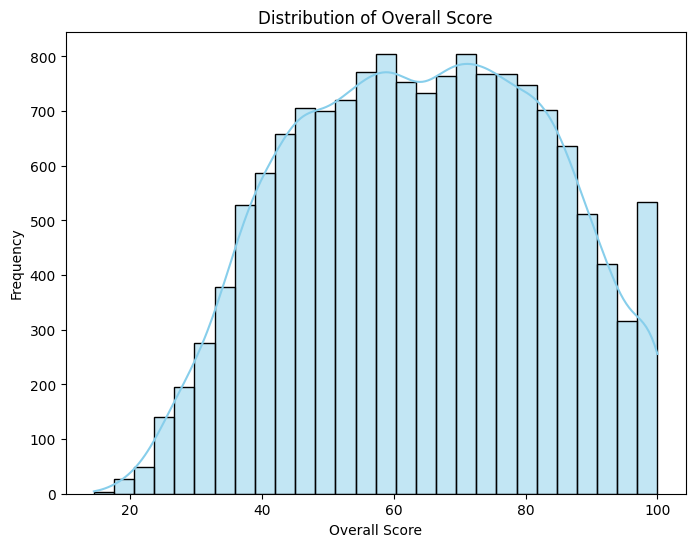

In [72]:
plt.figure(figsize=(8,6))
sns.histplot(x='overall_score',data=df,kde=True,bins=28,color='skyblue')
plt.title('Distribution of Overall Score')
plt.xlabel('Overall Score')
plt.ylabel('Frequency')
plt.savefig('/content/drive/MyDrive/aiml_datasets/outputs/charts/overall_score_distribution.png',bbox_inches='tight',dpi=300)
plt.show()

This graph shows the distribution of students' overall scores. Most students scored approximately between 40 and 90, while fewer students scored at the lower end. The pattern clearly shows that most students achieved moderate to high scores. This pattern may be related to factors such as preparation, study hours, and study habits.

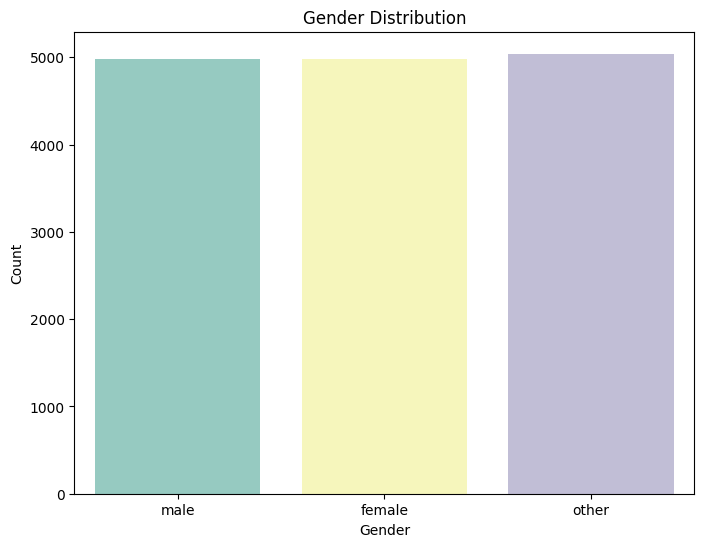

In [73]:
plt.figure(figsize=(8,6))
sns.countplot(x='gender',hue='gender',data=df,palette='Set3')
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.savefig('/content/drive/MyDrive/aiml_datasets/outputs/charts/gender_distribution.png',bbox_inches='tight',dpi=300)
plt.show()

This count plot shows the counts of the male, female, and other gender categories. All three categories have similar counts, with the 'other' category being slightly higher. The distribution is relatively balanced, with a similar number of students in each category.

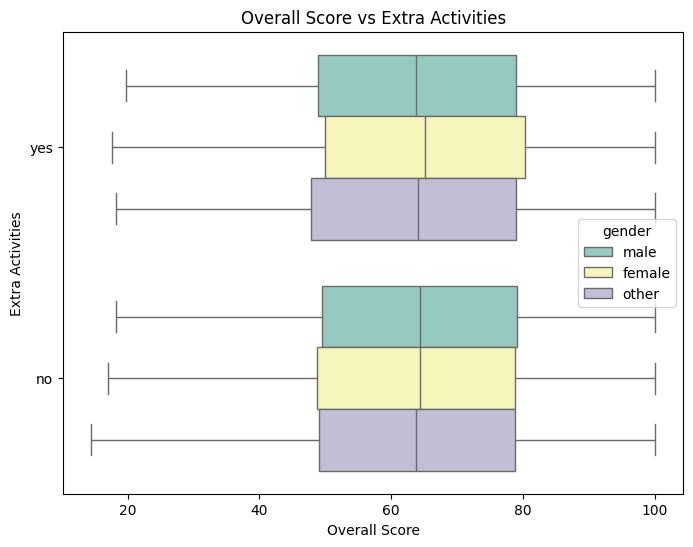

In [74]:
plt.figure(figsize=(8,6))
sns.boxplot(x='overall_score',y='extra_activities',data=df,hue='gender',palette='Set3')
plt.title("Overall Score vs Extra Activities")
plt.xlabel("Overall Score")
plt.ylabel("Extra Activities")
plt.savefig('/content/drive/MyDrive/aiml_datasets/outputs/charts/overall_score_vs_extra_activities.png',bbox_inches='tight',dpi=300)
plt.show()

This box plot shows students' overall scores based on extra activities and gender. There is no major difference in overall scores between the groups. The differences are weak or unclear, suggesting that participation in extra activities alone may not clearly distinguish students' overall scores.

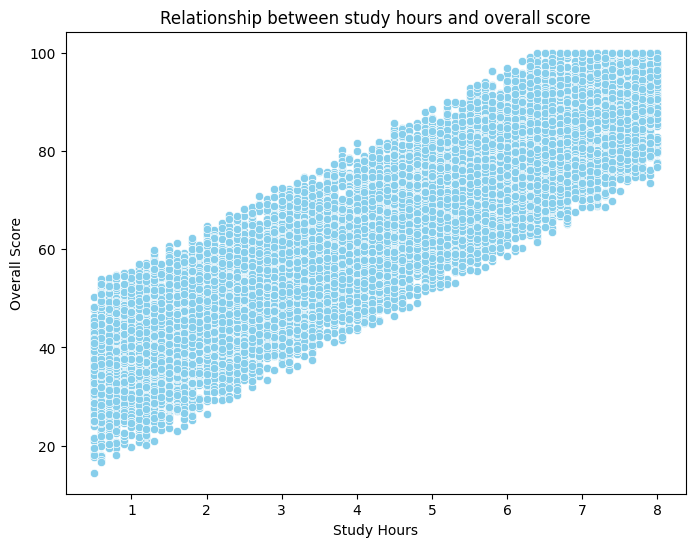

In [75]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='study_hours',y='overall_score',data=df,color='skyblue')
plt.title("Relationship between study hours and overall score")
plt.xlabel("Study Hours")
plt.ylabel("Overall Score")
plt.savefig('/content/drive/MyDrive/aiml_datasets/outputs/charts/study_hours_vs_overall_score.png',bbox_inches='tight',dpi=300)
plt.show()

This scatter plot shows the relationship between students' study hours and overall scores. A clear positive relationship can be observed, as students who study for more hours generally tend to achieve higher scores. The relationship is strong and positive, suggesting that study hours are closely associated with students' overall performance.

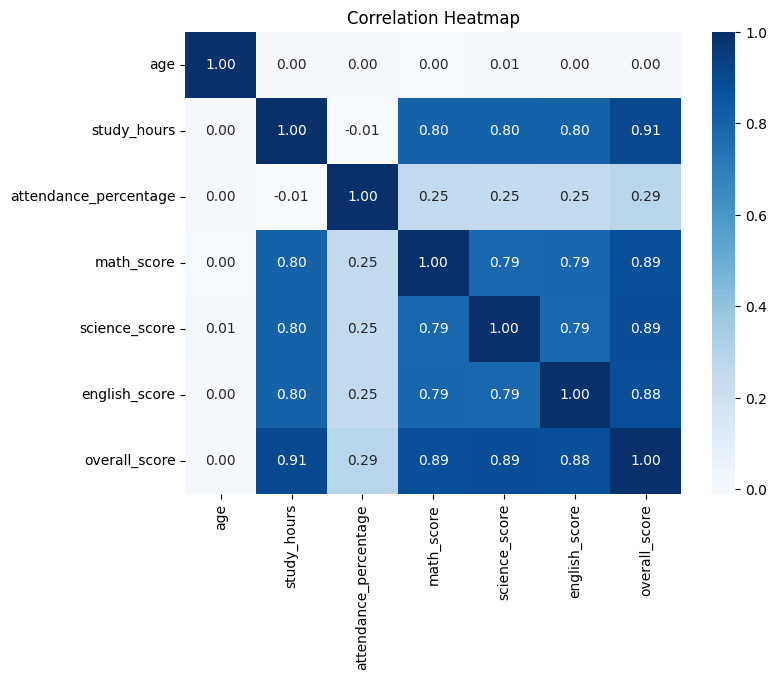

In [76]:
cols=['age','study_hours','attendance_percentage','math_score','science_score','english_score','overall_score']
plt.figure(figsize=(8,6))
corr=df[cols].corr()
sns.heatmap(corr,annot=True,fmt='.2f',cmap='Blues')
plt.title('Correlation Heatmap')
plt.savefig('/content/drive/MyDrive/aiml_datasets/outputs/charts/correlation_heatmap.png',bbox_inches='tight',dpi=300)
plt.show()

This heatmap shows the correlations between the numerical variables. Study hours have a very strong positive correlation with overall scores, approximately 0.91. Attendance percentage has a weak positive correlation with overall scores, approximately 0.29. Mathematics, Science, and English scores also have strong positive correlations with overall scores, approximately 0.88–0.89. No negative correlations are observed in the heatmap. Overall scores are strongly associated with study hours and subject scores, while the relationship with attendance is weaker. These findings suggest that study hours and subject performance are closely associated with overall results. However, correlation does not necessarily imply causation, because other factors may also influence academic performance. For example, study hours alone may not explain higher scores, as attendance and study methods may also be related to students' performance.